# Dreem Data Challenge 2023 : Automated Sleep Staging of the Dreem Headband data 

#### Léa Coquet and Nicolas Criscuolo

The objective of this challenge is to classify the sleep data collected by a Headband into the 5 sleep stages.
The Dreem Headband is composed of :
- 5 EEG sensors (sampled at 250 Hz) to measure EEG (2 frontal, 1 ground and 2 occipital sensors)
- 3D Acceleromter (sampled at 50Hz) to measure movements and head position
 
The goal is to have the best prediction of the sleep stages (Wake (0), N1 (1), N2 (2), N3 (3), REM (4) ) of each section of 30 seconds of data.

The performance of the prediction is mesured by using the Macro F1-score, which Weights equally precision and recall for all classes.

In [150]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
from scipy.signal import spectrogram, butter, lfilter, freqz
from scipy.stats import skew, kurtosis
from scipy.spatial.distance import pdist, squareform
from scipy.cluster import hierarchy

import matplotlib.pyplot as plt
import json
import os
import random as rd
import pandas as pd
import antropy
import mne_features

from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, cohen_kappa_score, confusion_matrix, classification_report, f1_score, ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_score, train_test_split, GridSearchCV
from xgboost import XGBClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as imbpipeline

# Pre-processing

In this section, we load the training data, which are then stored in dictionaries. 

The EEG dictionary contains, for each record, the 5 associated EEGs in dictionary format, and the AX dictionary contains, for each record, the 3 x, y or z acceleration signals.

When loading data, we tried adding two parameters: $\textit{filter}$ enables a Butterworth [1] bandpass filtration to be performed on the data, and $\textit{scaler}$ enables the data to be standardized with a Scaler (MinMax or Standard). We tried different combinations (before/after or with/without), but they didn't give us good results.

In [151]:
cd '/kaggle/input/automated-sleep-staging-beacon-biosignals-2023-2024'

[Errno 2] No such file or directory: '/kaggle/input/automated-sleep-staging-beacon-biosignals-2023-2024'
/Users/nico/Desktop/3A/CS/ML/Kaggle/automated-sleep-staging-beacon-biosignals-2023-2024


In [152]:
cd '/Users/nico/Desktop/3A/CS/ML/Kaggle/automated-sleep-staging-beacon-biosignals-2023-2024'

/Users/nico/Desktop/3A/CS/ML/Kaggle/automated-sleep-staging-beacon-biosignals-2023-2024


In [153]:
# Pre-processing part: load data + filter or/and scaler

# Butterworth filter
def butterworth_filter(data, lowcut, highcut, fs, order=8):
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band', analog=False)
    y = lfilter(b, a, data)
    return y

# Pre-process data
def pre_process(path, target_path=None, filter=False, scaler=False):
    EEG = {}
    AX = {}
    
    if target_path is not None:
        hypnogram_for_records = {}
        hypnograms = pd.read_csv('targets_train.csv')
    
    for record in os.listdir(path):
        print(record, " is loading")
        record_number = int(record[-5])

        # Load data
        x = np.load(f'{path}/{record}')
        data = [x[:,1:7501], x[:,7501:15001], x[:,15001:22501], x[:,22501:30001], x[:,30001:37501], x[:,37501:39001], x[:,39001:40501], x[:,40501:42001]]

        for i in range(len(data)):
            # Scaling data
            if scaler:
                data[i] = scaler.fit_transform(data[i])

            # Filtering data (Butterworth filter on EEG)
            if filter:
                data[i] = butterworth_filter(data[i], 0.01, 35, 250, order=8)
            
        # Save into dictionaries
        EEG[record] = {
            "EEG_1": data[0],
            "EEG_2": data[1],
            "EEG_3": data[2],
            "EEG_4": data[3],
            "EEG_5": data[4]
        }

        AX[record] = {
            "x": data[5],
            "y": data[6],
            "z": data[7]

        }

        if target_path is not None:
            hypnogram_for_records[record] = list(hypnograms[hypnograms['record'] == record_number]['target'])
    
    if target_path is not None:
        return EEG, AX, hypnogram_for_records
    return EEG, AX

In [154]:
# Load train data
EEG, AX, hypnogram_for_records = pre_process('training_records', 'targets_train.csv', filter=False, scaler=False)

dreem_0.npy  is loading
dreem_1.npy  is loading
dreem_3.npy  is loading
dreem_2.npy  is loading
dreem_6.npy  is loading
dreem_5.npy  is loading
dreem_4.npy  is loading


Let display an example of one entire file (dreem_0.npy) and its target (hypnogram).

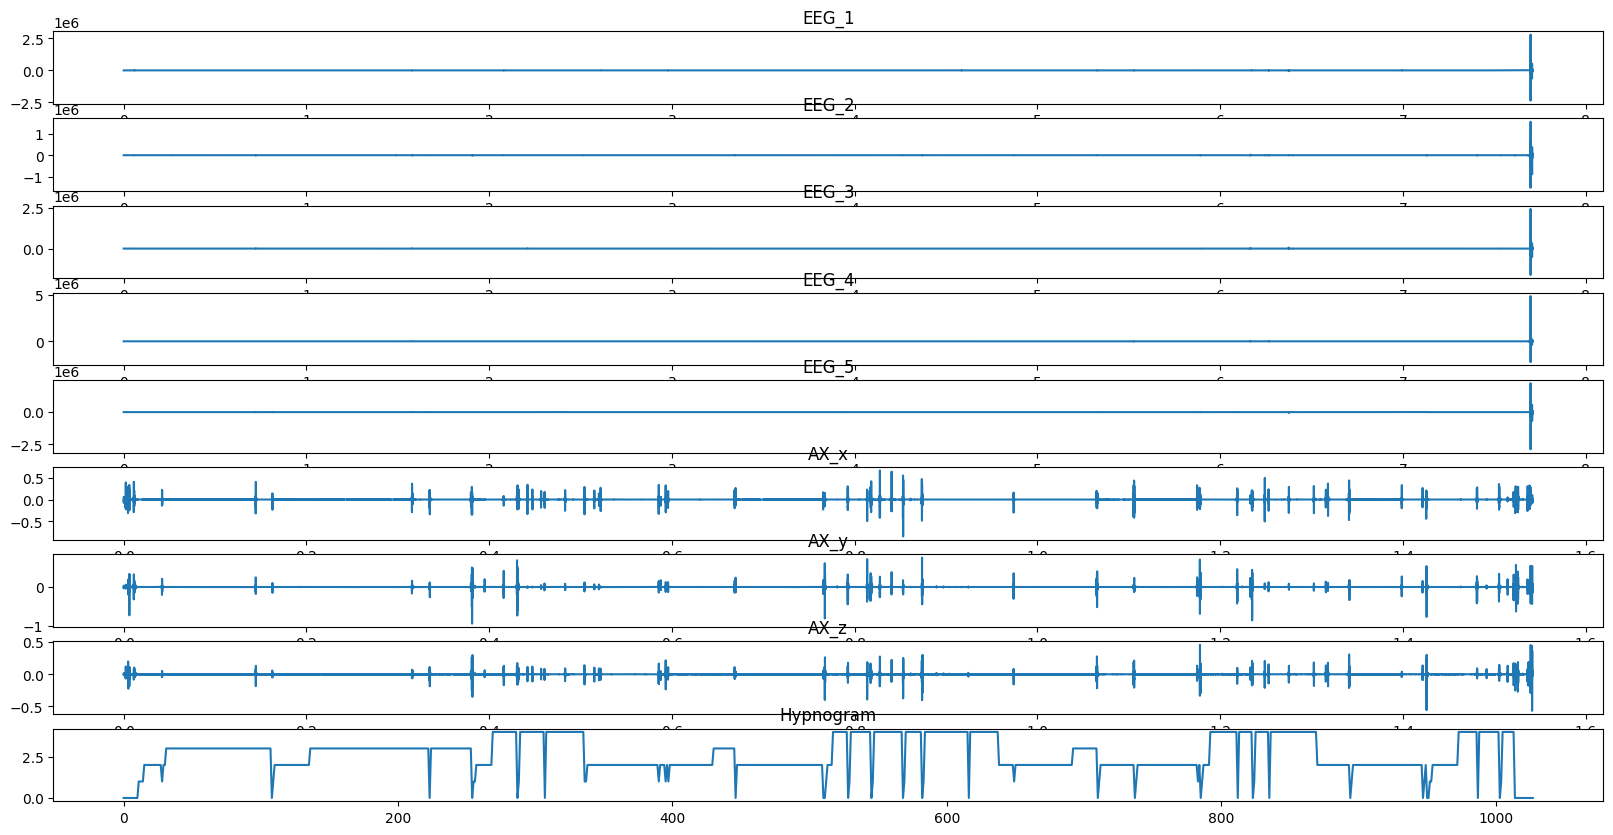

In [155]:
#display an example
plt.figure(figsize=(20,10))
plt.subplot(9, 1, 1)
plt.plot(EEG['dreem_0.npy']['EEG_1'].flatten())
plt.title('EEG_1')
plt.subplot(9, 1, 2)
plt.plot(EEG['dreem_0.npy']['EEG_2'].flatten())
plt.title('EEG_2')
plt.subplot(9, 1, 3)
plt.plot(EEG['dreem_0.npy']['EEG_3'].flatten())
plt.title('EEG_3')
plt.subplot(9, 1, 4)
plt.plot(EEG['dreem_0.npy']['EEG_4'].flatten())
plt.title('EEG_4')
plt.subplot(9, 1, 5)
plt.plot(EEG['dreem_0.npy']['EEG_5'].flatten())
plt.title('EEG_5')
plt.subplot(9, 1, 6)
plt.plot(AX['dreem_0.npy']['x'].flatten())
plt.title('AX_x')
plt.subplot(9, 1, 7)
plt.plot(AX['dreem_0.npy']['y'].flatten())
plt.title('AX_y')
plt.subplot(9, 1, 8)
plt.plot(AX['dreem_0.npy']['z'].flatten())
plt.title('AX_z')
plt.subplot(9, 1, 9)
plt.plot(hypnogram_for_records['dreem_0.npy'])
plt.title('Hypnogram')
plt.show()

As we can see, we have really high values for the EEG signals at the end: this may be cause by the patient when he gets awake by the end of the night.

We can see clearly the differents stages of the hypnogram, N1 stage suggests to be a transitory stage between AWAKE and N2.

# Feature Extraction

In this part, the goal is to extract relevant features 

In this section, the objective is to extract a maximum number of features that will subsequently be used to classify our dataset. A preliminary implementation was carried out in the Kaggle-provided practical works, which served as our inspiration. Primarily, we extract spectral and statistical data for each epoch.

For statistical data, we have chosen to extract, in addition to basic statistics:

- Skewness: Skewness is a statistical measure that quantifies the asymmetry of the distribution of values of a variable around its mean. It indicates how the tail of the distribution extends relative to the mean. A positive skewness suggests asymmetry where the right tail of the distribution is longer or more extended than the left, while a negative skewness suggests asymmetry where the left tail is longer or more extended than the right. A skewness of zero indicates a perfectly symmetrical distribution.

- Kurtosis: Kurtosis provides information about the tails of a distribution, helping to identify whether the data has more or fewer extreme values than a normal distribution.

- Quantiles and Inter-Quantile value ($q_{0.75} - q_{0.25}$)

- Spectral entropy (spen): Spen characterizes the disorder present in the frequency spectrum of a signal.

- Zero-crossings: this characterizes the number of times a signal crosses the zero axis.

- Higuchi fractal dimension [3]: The Higuchi fractal dimension is a measure of the fractal complexity of a time series. It quantifies how fluctuations at different time scales are related in the time series: the higher the fractal dimension, the more complex the time series and the more fluctuations there are at different time scales. It is calculated using the following formula: $ DH = \frac{\log(L)}{\log(k)} $, where $ L $ is the length of the time signal, and $ k $ is the number of sub-series used to measure the structure of the signal at different time scales.

- Katz fractal dimension [3]: The Katz fractal dimension is a measure of the fractal complexity of data, assessing how their structure changes at different resolution scales. It is calculated using the formula: $ DK = \frac{\log(N)}{\log(1/\varepsilon)} $, where $ N $ is the number of objects or points in the dataset, and $ \varepsilon $ is the resolution scale used to measure the shape of the object or dataset.

- Petrosian fractal dimension [3]: The Petrosian fractal dimension is a measure of the fractal complexity of a time signal, characterizing how the signal's structure changes at different time scales. It is calculated using the formula: $ DP = \frac{\log(N)}{\log(N_{\Delta})} $, where $ N $ is the length of the signal, and $ N_{\Delta} $ is the number of sign changes in the derivative of the signal.

- Hjorth parameters: The Hjorth parameters are measures of signal complexity, characterized by mobility (how quickly the signal changes) and complexity (correlation between different parts of the signal). These features are particularly suitable for the analysis of body movements from accelerometer data.

Furthermore, for the Acceleration data, we compute the general acceleration $acc = \sqrt{x''^2+y''^2+z''^2}$.

Finally, we have added a parameter in our extraction feature function. $\textit{split}$ is the number of split on each epoch. After applying the split, we compute independently each statistic or periodogram on the sub-signal and we compute also the difference between the actual split and the previous one: it gives an information on the variation of the feature for each epoch.

In [156]:
# Definition of some statistics functions

def petrosian_fd(x, axis=-1):
    x = np.asarray(x)
    N = x.shape[axis]
    nzc_deriv = antropy.num_zerocross(np.diff(x, axis=axis), axis=axis)
    pfd = np.log10(N) / (np.log10(N) + np.log10(N / (N + 0.4 * nzc_deriv))) 
    return pfd

def katz_fd(x, axis=-1):
    x = np.asarray(x)
    dists = np.abs(np.diff(x, axis=axis))
    ll = dists.sum(axis=axis)
    ln = np.log10(ll / dists.mean(axis=axis)) 
    aux_d = x - np.take(x, indices=[0], axis=axis) 
    d = np.max(np.abs(aux_d), axis=axis)
    kfd = np.squeeze(ln / (ln + np.log10(d / ll))) 
    if not kfd.ndim:
        kfd = kfd.item()
    return kfd

In [157]:
frequency_bands_EEG = {
    "delta": [0.5, 4],
    "theta": [4, 8],
    "alpha": [8, 12],
    "sigma": [12, 16],
    "beta": [16, 30],
    "sleep spindle": [12, 14],
    "K complex": [0.5, 1.5]
}

frequency_bands_ACC = {
    "slow": [0, 0.5],
    "slow_normal": [0.5, 1],
    "normal": [1, 4],
    "fast": [4, 10]  
}

statistics = {
    "stdev": lambda x:np.std(x,1),
    "var": lambda x:np.var(x,1),
    "mean": lambda x:np.mean(np.abs(x),1),
    "minimum": lambda x:np.min(x,1),
    "maximum": lambda x:np.max(x,1),
    "median": lambda x:np.median(x,1),
    "skewness": lambda x:skew(x,1),
    "kurtosis": lambda x:kurtosis(x,1),
    "Q25": lambda x:np.quantile(x,0.25,1),
    "Q75": lambda x:np.quantile(x,0.75,1),
    "IQR": lambda x:np.quantile(x,0.75,1)-np.quantile(x,0.25,1),
    "spen": lambda x: antropy.spectral_entropy(x, sf=250, method='welch', normalize=True, axis=1),
    "zero_cross": lambda x: antropy.num_zerocross(x, axis=1)
}

features_mne = {
    "higuchi":lambda x: mne_features.univariate.compute_higuchi_fd(x, kmax=10),
    "ptp":lambda x: mne_features.univariate.compute_ptp_amp(x),
    "samp_entropy":lambda x: mne_features.univariate.compute_ptp_amp(x),
    "hjorth_mob":lambda x: mne_features.univariate.compute_hjorth_mobility(x),
    "hjorth_compl":lambda x: mne_features.univariate.compute_hjorth_complexity(x),
    "katz":lambda x: katz_fd(x),
    "petrosian":lambda x: petrosian_fd(x)
}

def acceleration(ax, ay, az):
    return np.sqrt(ax**2 + ay**2 + az**2)
def speed(ax, ay, az):
    return np.cumsum(acceleration(ax, ay, az))

def get_relative_spectral_power_for_epoch(data, frequency_bands, FS, nperseg = 1000,noverlap = 750):
    """
    Compute the relative spectral power for each of the frequency bands defined above
    """
    sfreqs, t, psd = spectrogram(data, FS, nperseg = nperseg, noverlap = noverlap)
    psd = np.mean(np.abs(psd),-1)
    spectral_power_band = {}
    for name, freqband in frequency_bands.items():
        spec_power = psd[:,(sfreqs >= freqband[0]) & (sfreqs < freqband[1])]
        spec_power = np.sum(spec_power, 1)
        spectral_power_band[name] = spec_power / np.sum(psd,1)
    return spectral_power_band

def compute_stats(data, stat_dic):
    """
    Compute the statistics of a signal from stat_dic statistics
    """
    result = {k:f(data) for k,f in stat_dic.items()}
    return result

# Function feature_extraction_split which compute the same stats but by splitting each epoch into sub-epochs, compute also differences between sub-epochs
def feature_extraction_split(EEG, AX, split=1):
    EEG_features = {}

    AX_features = {}
    
    # Extract features from data
    for record in list(EEG.keys()):
        print("Extracting features from: ", record)
        record_number = int(record[-5])

        split_EEG_size = int(len(EEG[record]["EEG_1"][0]) / split)
        split_AX_size = int(len(AX[record]["x"][0]) / split)

        # Compute features from EEG
        for i in range(5):
            for k in range(split):
                # Compute values for each sub-epoch
                sp = get_relative_spectral_power_for_epoch(EEG[record][f"EEG_{i+1}"][:, k*split_EEG_size:(k+1)*split_EEG_size], frequency_bands_EEG, 250)
                stat = compute_stats(EEG[record][f"EEG_{i+1}"][:, k*split_EEG_size:(k+1)*split_EEG_size], statistics)
                stat_mne = compute_stats(EEG[record][f"EEG_{i+1}"][:, k*split_EEG_size:(k+1)*split_EEG_size], features_mne)

                if record not in EEG_features.keys():
                    EEG_features[record] = {f"EEG_{i+1}_{key}_{k}": value for key, value in sp.items()}
                else:
                    EEG_features[record].update({f"EEG_{i+1}_{key}_{k}": value for key, value in sp.items()})
                EEG_features[record].update({f"EEG_{i+1}_{key}_{k}": value for key, value in stat.items()})
                EEG_features[record].update({f"EEG_{i+1}_{key}_{k}": value for key, value in stat_mne.items()})

                # Compute differences between sub-epochs
                if k > 0:
                    sp_diff = {f"EEG_{i+1}_{key}_diff_{k}": sp[key] - EEG_features[record][f"EEG_{i+1}_{key}_{k-1}"] for key in sp.keys()}
                    stat_diff = {f"EEG_{i+1}_{key}_diff_{k}": stat[key] - EEG_features[record][f"EEG_{i+1}_{key}_{k-1}"] for key in stat.keys()}
                    stat_mne_diff = {f"EEG_{i+1}_{key}_diff_{k}": stat_mne[key] - EEG_features[record][f"EEG_{i+1}_{key}_{k-1}"] for key in stat_mne.keys()}
                    EEG_features[record].update(sp_diff)
                    EEG_features[record].update(stat_diff)
                    EEG_features[record].update(stat_mne_diff)
        
        # Compute features from AX
        for k in range(split):
            # Compute values for each sub-epoch
            acc = acceleration(AX[record]["x"][:, k*split_AX_size:(k+1)*split_AX_size], AX[record]["y"][:, k*split_AX_size:(k+1)*split_AX_size], AX[record]["z"][:, k*split_AX_size:(k+1)*split_AX_size])
            velocity = speed(AX[record]["x"][:, k*split_AX_size:(k+1)*split_AX_size], AX[record]["y"][:, k*split_AX_size:(k+1)*split_AX_size], AX[record]["z"][:, k*split_AX_size:(k+1)*split_AX_size])
            
            stat_acc = compute_stats(acc, statistics)
            stat_velocity = compute_stats(velocity, statistics)
            stat_x = compute_stats(AX[record]["x"][:, k*split_AX_size:(k+1)*split_AX_size], statistics)
            stat_y = compute_stats(AX[record]["y"][:, k*split_AX_size:(k+1)*split_AX_size], statistics)
            stat_z = compute_stats(AX[record]["z"][:, k*split_AX_size:(k+1)*split_AX_size], statistics)

            sp_acc = get_relative_spectral_power_for_epoch(acc, frequency_bands_ACC, 50, nperseg = 500, noverlap = 400)
            sp_x = get_relative_spectral_power_for_epoch(AX[record]["x"][:, k*split_AX_size:(k+1)*split_AX_size], frequency_bands_ACC, 50, nperseg = 500, noverlap = 400)
            sp_y = get_relative_spectral_power_for_epoch(AX[record]["y"][:, k*split_AX_size:(k+1)*split_AX_size], frequency_bands_ACC, 50, nperseg = 500, noverlap = 400)
            sp_z = get_relative_spectral_power_for_epoch(AX[record]["z"][:, k*split_AX_size:(k+1)*split_AX_size], frequency_bands_ACC, 50, nperseg = 500, noverlap = 400)

            if record not in AX_features.keys():
                AX_features[record] = {f"{key}_acc_{k}": value for key, value in stat_acc.items()}
            else:
                AX_features[record].update({f"{key}_acc_{k}": value for key, value in stat_acc.items()})
            AX_features[record].update({f"{key}_x_{k}": value for key, value in stat_x.items()})
            AX_features[record].update({f"{key}_y_{k}": value for key, value in stat_y.items()})
            AX_features[record].update({f"{key}_z_{k}": value for key, value in stat_z.items()})
            AX_features[record].update({f"{key}_velocity_{k}": value for key, value in stat_velocity.items()})
            AX_features[record].update({f"{key}_acc_{k}": value for key, value in sp_acc.items()})
            AX_features[record].update({f"{key}_x_{k}": value for key, value in sp_x.items()})
            AX_features[record].update({f"{key}_y_{k}": value for key, value in sp_y.items()})
            AX_features[record].update({f"{key}_z_{k}": value for key, value in sp_z.items()})

            # Compute differences between sub-epochs
            if k > 0:
                acc_diff = {f"{key}_acc_diff_{k}": stat_acc[key] - AX_features[record][f"{key}_acc_{k-1}"] for key in stat_acc.keys()}
                velocity_diff = {f"{key}_velocity_diff_{k}": stat_velocity[key] - AX_features[record][f"{key}_velocityZ_{k-1}"] for key in stat_velocity.keys()}
                x_diff = {f"{key}_x_diff_{k}": stat_x[key] - AX_features[record][f"{key}_x_{k-1}"] for key in stat_x.keys()}
                y_diff = {f"{key}_y_diff_{k}": stat_y[key] - AX_features[record][f"{key}_y_{k-1}"] for key in stat_y.keys()}
                z_diff = {f"{key}_z_diff_{k}": stat_z[key] - AX_features[record][f"{key}_z_{k-1}"] for key in stat_z.keys()}
                acc_diff.update({f"{key}_acc_diff_{k}": sp_acc[key] - AX_features[record][f"{key}_acc_{k-1}"] for key in sp_acc.keys()})
                x_diff.update({f"{key}_x_diff_{k}": sp_x[key] - AX_features[record][f"{key}_x_{k-1}"] for key in sp_x.keys()})
                y_diff.update({f"{key}_y_diff_{k}": sp_y[key] - AX_features[record][f"{key}_y_{k-1}"] for key in sp_y.keys()})
                z_diff.update({f"{key}_z_diff_{k}": sp_z[key] - AX_features[record][f"{key}_z_{k-1}"] for key in sp_z.keys()})

                AX_features[record].update(**acc_diff, **velocity_diff, **x_diff, **y_diff, **z_diff)
        
    return EEG_features, AX_features

In [158]:
# Extract features from data
EEG_features, AX_features = feature_extraction_split(EEG, AX, 3)

Extracting features from:  dreem_0.npy
Extracting features from:  dreem_1.npy
Extracting features from:  dreem_3.npy
Extracting features from:  dreem_2.npy
Extracting features from:  dreem_6.npy
Extracting features from:  dreem_5.npy
Extracting features from:  dreem_4.npy


# Build dataset

After extracting features from pre-processed data, we construct the dataset in order to apply classification algorithms on it. We have modified and simplified the proposed code in the TP thanks to the $\textit{pandas}$ library and we also extract new features by applying a rolling average on each feature with a window which extracts only past data and anothr which extracts only future data. We have tested the classification task with a size window of 5 or 8 and we obtain similar results.

In [159]:
def build_dataset(records, EEG_features, AX_features, hypnogram=None, rolling=8):
    df, y = pd.DataFrame(), []

    for record in records:
        if hypnogram is not None:
            y.extend(hypnogram[record])
        
        ECF_df = pd.DataFrame(EEG_features[record])
        AX_df = pd.DataFrame(AX_features[record])

        # Rolling mean: past and future
        ECF_rolling = ECF_df.rolling(rolling).mean()
        AX_rolling = AX_df.rolling(rolling).mean()

        # Past and fillna with mean values
        ECF_rolling_past = ECF_rolling.fillna(ECF_rolling.mean()).add_prefix('past_')
        AX_rolling_past = AX_rolling.fillna(AX_rolling.mean()).add_prefix('past_')

        # Future and fillna with mean values
        ECF_rolling_future = ECF_rolling.shift(-rolling+1).fillna(ECF_rolling.mean()).add_prefix('future_')
        AX_rolling_future = AX_rolling.shift(-rolling+1).fillna(AX_rolling.mean()).add_prefix('future_')

        # Concatenate
        ECF_df = pd.concat([ECF_df, ECF_rolling_past, ECF_rolling_future], axis=1)
        AX_df = pd.concat([AX_df, AX_rolling_past, AX_rolling_future], axis=1)
        df = pd.concat([df, pd.concat([ECF_df, AX_df], axis=1)], axis=0)

    if hypnogram is not None:
        return df, y
    return df

In [160]:
# Test on the whole dataset
df, y = build_dataset(EEG_features.keys(), EEG_features, AX_features, hypnogram_for_records, rolling=8)

In [161]:
df.shape

(6175, 3390)

Finally, we obtain 3390 features. We can have some redundance between features which is dangerous in Machine Learning as it increases the variance of the estimator, reduces interpretability and increases computational time.

In the following section, we apply a simple feature selection which identifies null variance feature (no information) and multi-colinearity between features.

# Feature Selection

## Variance Threshold

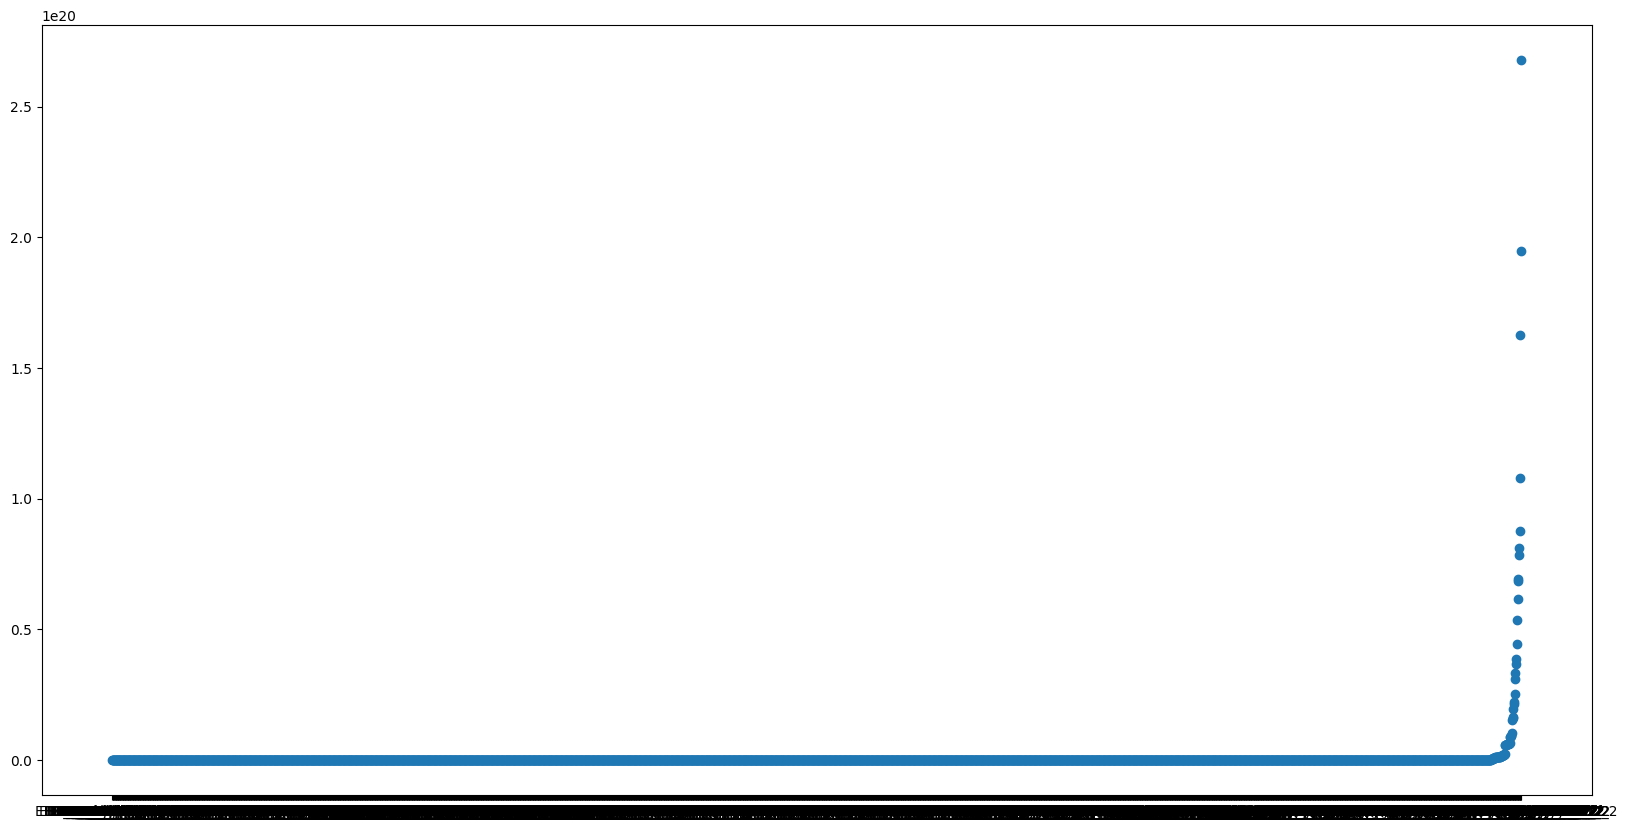

zero_cross_acc_0                0.000000e+00
future_zero_cross_acc_2         0.000000e+00
future_zero_cross_acc_diff_1    0.000000e+00
future_zero_cross_acc_1         0.000000e+00
future_zero_cross_acc_0         0.000000e+00
                                    ...     
EEG_4_var_0                     8.757719e+19
EEG_1_var_diff_1                1.078963e+20
EEG_4_var_diff_2                1.624930e+20
EEG_4_var_1                     1.946485e+20
EEG_4_var_diff_1                2.677892e+20
Length: 3390, dtype: float64
Number of features with 0 variance:  15
Number of features left:  3375


In [162]:
# Plot variances in the dataset
plt.figure(figsize=(20,10))
plt.scatter(df.columns, df.var().sort_values())
plt.show()

# Print sorted variances in the dataset
print(df.var().sort_values())
print("Number of features with 0 variance: ", len(df.var()[df.var() == 0]))

# Drop null variance columns
df = df.loc[:, df.var() != 0]

# Print the number of features left
print("Number of features left: ", len(df.columns))

We drop every feature with 0 variance.

## Remove multi-colinearity in the dataset

In [163]:
# Parameter
correlation_threshold = 0.95

# distance matrix
corr = pdist(df.to_numpy().T, metric="correlation")

# Compute the clusters
corr_linkage = hierarchy.average(corr)
cluster_ids = hierarchy.fcluster(
    corr_linkage, 1 - correlation_threshold, criterion="distance"
)
# for each cluster, only keep the first feature
keep_features = list()
for cluster in np.unique(cluster_ids):
    cluster_indexes = np.where(cluster_ids == cluster)[0]
    keep_features.append(df.columns[cluster_indexes[0]])

# Reduce the number of features
df_corr = df.copy()
df = df[keep_features]

# Print the number of features
print("Number of features before correlation filter: ", len(df_corr.columns))
print("Number of features after correlation filter: ", len(df.columns))

Number of features before correlation filter:  3375
Number of features after correlation filter:  2532


We have chosen a high correlation threshold which keeps 2/3 of initial features. 

We have chosen not to apply PCA algorithms as it creates new features based on linear combinations of the initial ones. We may use for example supervised or unsupervised filter methods such as Fisher Score (Supervised) or Laplacian Score (Unsupervised) [2]. We didn't have enough time to try this feature selection idea. However, in the next part we have chosen to use a XGBoost Classifier which determines by itself important features by supervised method.

# Classification

In this part, we are going to create a pipeline in order to apply different classifiers.

First, we perform a train/test split and, we keep 10% of train data in order to test it and compute F-Scores.

Then, looking at the distribution of classes in our dataset, we can see that the Wake and N1 classes are under-represented.
This imbalance in the dataset is disturbing because our models will find it harder to identify the minority classes, since they learn a bias from the majority classes.
Contrary to accuracy, which can be misleading for unbalanced datasets, the evaluation metric chosen (Macro F1-score) is a good indicator of performance because it reflects the state of learning of the model. To overcome this problem, we chose to carry out oversampling on minority classes using the SMOTE (Synthetic Minority Oversampling Technique) method. This technique makes it possible to generate new minority individuals that resemble the others, without being strictly identical, which makes it possible to densify in a more homogeneous way.

In [ ]:
count = np.array(y)
counts = np.array([np.count_nonzero(count == 0), np.count_nonzero(count == 1),np.count_nonzero(count == 2),np.count_nonzero(count == 3),np.count_nonzero(count == 4)])

fig = plt.figure()
ax = fig.add_axes([0,0,1,1])
stade = ['Wake', 'N1', 'N2', 'N3', 'REM']
ax.bar(stade,counts)
plt.title("Sleep stage distribution in train dataset")
plt.show()

We scale the data with a StandardScaler before training it. We perform also a GridSearch in order to optimize certains hyper-parameters and we use a 5-Fold Cross Validation during training.

In [164]:
# Train test split
X_train, X_test, y_train, y_test = train_test_split(df, y, test_size=0.1, random_state=42)

# OverSampling on train data
sm = SMOTE(random_state=42)
X_train, y_train = sm.fit_resample(X_train, y_train)

# Pipeline for training a model
def create_pipeline(model, params, cv=5):
    pipeline = imbpipeline([
        ('scaler', StandardScaler()),
        ('model', model)
    ])
    grid = GridSearchCV(pipeline, params, cv=cv, scoring='balanced_accuracy', n_jobs=-1, verbose=0)
    return grid 

## Logistic Regression

Logistic regression has been implemented in the TP and we tried this most-known multi-class classification.

/Users/nico/Desktop/3A/CS/ML/Kaggle/.conda/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/nico/Desktop/3A/CS/ML/Kaggle/.conda/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stab

{'model__C': 0.1}
0.9651450378159012
0.7197769647237516
              precision    recall  f1-score   support

           0       0.49      0.45      0.47        38
           1       0.26      0.36      0.30        25
           2       0.93      0.90      0.91       234
           3       0.94      0.97      0.95       140
           4       0.94      0.92      0.93       181

    accuracy                           0.87       618
   macro avg       0.71      0.72      0.71       618
weighted avg       0.88      0.87      0.88       618



/Users/nico/Desktop/3A/CS/ML/Kaggle/.conda/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


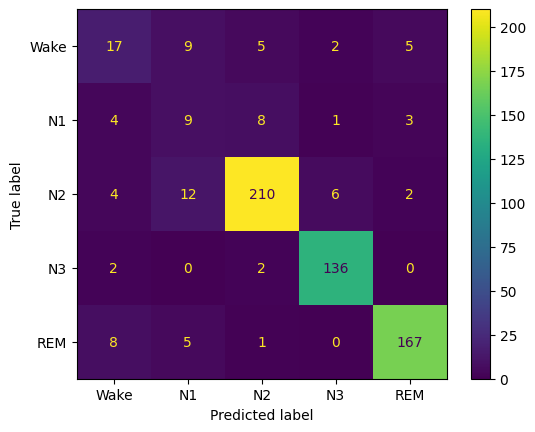

In [165]:
# Logistic Regression Grid Search
lr_params = {
    'model__C': [0.01, 0.1, 1, 10, 100]
}

lr_grid = create_pipeline(LogisticRegression(), lr_params, cv=5)
lr_grid.fit(X_train, y_train)
print(lr_grid.best_params_)
print(lr_grid.best_score_)
print(lr_grid.score(X_test, y_test))

# Classification report
print(classification_report(y_test, lr_grid.best_estimator_.predict(X_test)))

# Confusion matrix
ConfusionMatrixDisplay.from_estimator(lr_grid.best_estimator_, X_test,y_test,display_labels = ['Wake','N1','N2','N3','REM'])

We can see that we obtain good results on N3, N4 and REM but lower F-Scores for N1 and Wake. Despite the Smote stage, we may overfit the data for this stage and we cannot generalize for test data.

## Random Forest

In [ ]:
# Random Forest grid search
rf_params = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [None, 5, 10, 15],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 5]
}

rf_grid = create_pipeline(RandomForestClassifier(), rf_params, cv=5)
rf_grid.fit(X_train, y_train)
print(rf_grid.best_params_)
print(rf_grid.best_score_)
print(rf_grid.score(X_test, y_test))

# Classification report
print(classification_report(y_test, rf_grid.best_estimator_.predict(X_test)))

# Confusion matrix
ConfusionMatrixDisplay.from_estimator(rf_grid.best_estimator_, X_test,y_test,display_labels = ['Wake','N1','N2','N3','REM'])

## XGBoost [4]

**XGBoost: eXtreme Gradient Boosting**

*Boosting Overview:*
- Boosting combines weak learners to form a strong learner.
- Weak learners perform slightly better than random chance.
- Boosting sequentially trains weak learners, emphasizing misclassified instances.

*XGBoost Specifics:*
- XGBoost enhances boosting with regularization and parallel computing.
- It optimizes a loss function through iterative addition of weak learners.

*Objective Function:*
$$
\text{Obj} = \sum_{i=1}^{n} L(y_i, \hat{y}_i) + \sum_{k=1}^{K} \Omega(f_k)
$$
where $ L $ is the loss function, $ y_i $ is true labels, $ \hat{y}_i $ is predicted values, and $ \Omega(f_k) $ is the regularization term for the $ k $-th tree.

*Training Process:*
1. **Initialize with a Constant Prediction:** $ \hat{y}_i = \bar{y} $
2. **Compute Residuals:** $ r_{i} = y_i - \hat{y}_i $
3. **Fit a Weak Learner (Decision Tree):** $ f_k = \text{argmin}_f \sum_{i=1}^{n} L(y_i, \hat{y}_i + f_k(x_i)) $
4. **Update Predictions:** $ \hat{y}_i \leftarrow \hat{y}_i + \eta \times f_k(x_i) $ (Repeat for a predefined number of iterations)

*Regularization:*
- XGBoost includes regularization terms in the objective function.
- These terms control the model's complexity, preventing overfitting and enhancing generalization.


Fitting 5 folds for each of 1 candidates, totalling 5 fits
{'model__learning_rate': 0.1, 'model__max_depth': None, 'model__n_estimators': 300}
0.9739778177458034
0.7786879168455207
              precision    recall  f1-score   support

           0       0.66      0.71      0.68        38
           1       0.40      0.32      0.36        25
           2       0.94      0.94      0.94       234
           3       0.96      0.96      0.96       140
           4       0.95      0.96      0.95       181

    accuracy                           0.91       618
   macro avg       0.78      0.78      0.78       618
weighted avg       0.91      0.91      0.91       618



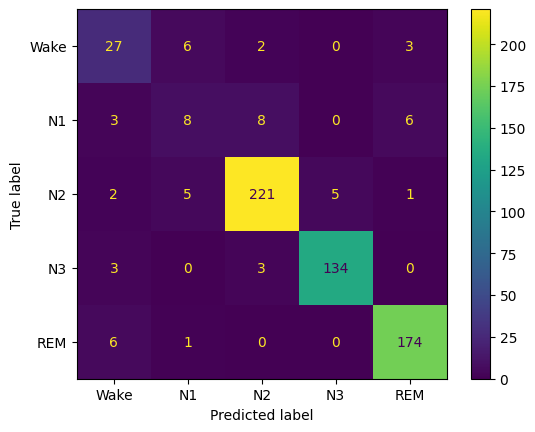

In [167]:
# XGBoost Grid Search
xgb_params = {
    'model__n_estimators': [300],
    'model__max_depth': [None],
    'model__learning_rate': [0.1]
}

xgb_grid = create_pipeline(XGBClassifier(), xgb_params, cv=5)
xgb_grid.fit(X_train, y_train)
print(xgb_grid.best_params_)
print(xgb_grid.best_score_)
print(xgb_grid.score(X_test, y_test))

# Classification report
print(classification_report(y_test, xgb_grid.best_estimator_.predict(X_test)))

# Confusion matrix
ConfusionMatrixDisplay.from_estimator(xgb_grid.best_estimator_, X_test,y_test,display_labels = ['Wake','N1','N2','N3','REM'])

We obtain better results, especially for Wake category. However, the weakness of the model is the capacity of discriminating N1 and N2 classes. 

# Make submissions

The following cell allows to predict the test data and save predictions in the submission folder.

In [130]:
# Create test data for submission
EEG_test, AX_test = pre_process('test_records', filter=False, scaler=False)

EEG_features_test, AX_features_test = feature_extraction_split(EEG_test, AX_test, 3)

df_test = build_dataset(EEG_features_test.keys(), EEG_features_test, AX_features_test)

df_test = df_test.loc[:, df_test.var() != 0]
df_test = df_test[keep_features]

# Predict on test data
y_pred = xgb_grid.best_estimator_.predict(df_test)

# Create submission file
identifier = []
for record in os.listdir("test_records"):
    record_number = int(record[-5])
    x = np.load(f'test_records/{record}')
    for i in range(len(x)):
        identifier.append(record_number * 10000 + i)

predictions = pd.DataFrame({'identifier': identifier, 'target': y_pred})
#predictions.to_csv('/kaggle/working/submission.csv',index = None)
predictions


dreem_7.npy  is loading
dreem_9.npy  is loading
dreem_8.npy  is loading
Extracting features from:  dreem_7.npy
Extracting features from:  dreem_9.npy
Extracting features from:  dreem_8.npy


,identifier,target
0,70000,0
1,70001,0
2,70002,0
3,70003,0
4,70004,0
...,...,...
2641,80931,4
2642,80932,2
2643,80933,2
2644,80934,2


# Conclusion

Thanks to the study we carried out on the data, features and models, we finally obtained a score of thanks to the XGBoost algorithm.

The data processing is a really important step, and if we had more time, we could explore our data more and work on feature selection.

# Reference

[1] Aboalayon, Khald & Faezipour, Miad & Almuhammadi, Wafaa & Moslehpour, Saeid. (2016). Sleep Stage Classification Using EEG Signal Analysis: A Comprehensive Survey and New Investigation. Entropy. 18. 10.3390/e18090272.

[2] Xiaofei He, Deng Cai, and Partha Niyogi. Laplacian score for feature selection. Computers and Typesetting, 2005.

[3] Esteller, Rosana & Vachtsevanos, George & Echauz, Javier & Litt, Brian. (2001). A Comparison of waveform fractal dimension algorithms. Circuits and Systems I: Fundamental Theory and Applications, IEEE Transactions on. 48. 177 - 183. 10.1109/81.904882.

[4] Chen, Tianqi & Guestrin, Carlos. (2016). XGBoost: A Scalable Tree Boosting System. 785-794. 10.1145/2939672.2939785.